*Commentary pending: intro.*

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

warnings.filterwarnings("ignore")
COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
OUTPUTS = Path.cwd().parent / "outputs"
MODEL_COLORS = {"logistic": "#2a78d6", "boosting": "#eb6834", "gru": "#1baf7a"}
NAMES = {
    "party_line": "Everyone votes with their party", "training_rate": "Training-period defection rate",
    "own_past_rate": "Own past rate on this kind of vote", "logistic": "Logistic regression",
    "boosting": "Gradient boosting", "gru_seed0": "GRU, seed 0", "gru_seed1": "GRU, seed 1", "gru_seed2": "GRU, seed 2",
    "gru_mean": "GRU, average of 3 seeds", "boosting_with_split": "Gradient boosting + party split sizes (after the vote)",
}
predictions = pd.read_parquet(OUTPUTS / "predictions.parquet")
predictions["p_gru_mean"] = predictions[["p_gru_seed0", "p_gru_seed1", "p_gru_seed2"]].mean(axis=1)
predictions["defected"] = predictions["defected"].astype(bool)
run_log = (OUTPUTS / "run_log.txt").read_text(encoding="utf-8").splitlines()
print("Model choices on the validation years:")
print("\n".join(line for line in run_log if "best number of trees" in line or "epoch" in line))
test = predictions[predictions["split"] == "test"]
valid = predictions[predictions["split"] == "validation"]
for name, part in [("Validation, 2011 to 2014", valid), ("Test, 2015 to 2024", test)]:
    print(f"{name}: {len(part):,} votes on {part[['congress', 'chamber', 'rollnumber']].drop_duplicates().shape[0]:,} roll calls, "
          f"{part['person'].nunique():,} members; defection rate {part['defected'].mean():.4f}, "
          f"{part['party_opposed'].mean():.1%} of votes on party-opposed roll calls")


Model choices on the validation years:
boosting: best number of trees 120 of 600, validation log loss 0.2456
boosting+split: best number of trees 287 of 600, validation log loss 0.1858
seed 0 epoch 1: train log loss 0.3359, validation log loss 0.2539
seed 0 epoch 2: train log loss 0.3057, validation log loss 0.2427
seed 0 epoch 3: train log loss 0.2949, validation log loss 0.2402
seed 0 epoch 4: train log loss 0.2909, validation log loss 0.2406
seed 0 epoch 5: train log loss 0.2875, validation log loss 0.2390
seed 0 epoch 6: train log loss 0.2847, validation log loss 0.2372
seed 0 epoch 7: train log loss 0.2820, validation log loss 0.2435
seed 0 epoch 8: train log loss 0.2794, validation log loss 0.2389
seed 1 epoch 1: train log loss 0.3347, validation log loss 0.2563
seed 1 epoch 2: train log loss 0.3054, validation log loss 0.2453
seed 1 epoch 3: train log loss 0.2948, validation log loss 0.2389
seed 1 epoch 4: train log loss 0.2909, validation log loss 0.2385
seed 1 epoch 5: train l

Validation, 2011 to 2014: 1,114,211 votes on 3,417 roll calls, 646 members; defection rate 0.0919, 82.6% of votes on party-opposed roll calls
Test, 2015 to 2024: 2,323,383 votes on 8,028 roll calls, 883 members; defection rate 0.0654, 80.1% of votes on party-opposed roll calls


*Commentary pending: setup.*

## How do the models compare on the test years?

In [2]:
def metrics(part, column):
    y, p = part["defected"].to_numpy(), part[column].to_numpy()
    flipped = p > 0.5
    k = int(y.sum())
    top = np.zeros(len(p), dtype=bool)
    top[np.argsort(-p, kind="stable")[:k]] = True
    opposed = part["party_opposed"].to_numpy()
    return {
        "accuracy, all votes": np.mean(flipped == y),
        "accuracy, party-opposed": np.mean((flipped == y)[opposed]),
        "defection AUC": roc_auc_score(y, p) if np.ptp(p) > 0 else 0.5,
        "average precision": average_precision_score(y, p),
        "log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
        "defections caught at 0.5": (flipped & y).sum() / k,
        "precision at 0.5": (flipped & y).sum() / max(flipped.sum(), 1),
        "caught when flagging as many as defect": (top & y).sum() / k,
        "mean prediction": p.mean(),
    }


ORDER = ["party_line", "training_rate", "own_past_rate", "logistic", "boosting", "gru_seed0", "gru_seed1", "gru_seed2", "gru_mean",
         "boosting_with_split"]


def table(part):
    return pd.DataFrame({NAMES[m]: metrics(part, f"p_{m}") for m in ORDER}).T


print(f"Test, 2015 to 2024. Defection rate {test['defected'].mean():.4f}; a model with no information has average precision equal to it.")
display(table(test).round(4))
print("Validation, 2011 to 2014 (used to choose the number of trees and GRU epochs):")
display(table(valid)[["accuracy, all votes", "defection AUC", "average precision", "log loss"]].round(4))
for chamber in ["House", "Senate"]:
    part = test[test["chamber"] == chamber]
    print(f"Test, {chamber}: {len(part):,} votes, defection rate {part['defected'].mean():.4f}")
    display(table(part)[["accuracy, all votes", "accuracy, party-opposed", "defection AUC", "average precision",
                         "caught when flagging as many as defect"]].round(4))


Test, 2015 to 2024. Defection rate 0.0654; a model with no information has average precision equal to it.


,"accuracy, all votes","accuracy, party-opposed",defection AUC,average precision,log loss,defections caught at 0.5,precision at 0.5,caught when flagging as many as defect,mean prediction
Everyone votes with their party,0.9346,0.9520,0.5000,0.0654,0.9034,0.0000,0.0000,0.0623,0.0000
Training-period defection rate,0.9346,0.9520,0.5000,0.0654,0.2577,0.0000,0.0000,0.0623,0.1193
Own past rate on this kind of vote,0.9365,0.9520,0.7730,0.2725,0.2095,0.0639,0.6504,0.3156,0.0730
Logistic regression,0.9383,0.9532,0.8305,0.3662,0.1911,0.1390,0.6258,0.4022,0.0796
Gradient boosting,0.9386,0.9540,0.8503,0.3863,0.1813,0.1283,0.6581,0.4178,0.0709
"GRU, seed 0",0.9399,0.9543,0.8578,0.4159,0.1780,0.1623,0.6676,0.4390,0.0762
"GRU, seed 1",0.9400,0.9547,0.8603,0.4152,0.1753,0.2009,0.6297,0.4373,0.0694
"GRU, seed 2",0.9402,0.9546,0.8565,0.4132,0.1778,0.1966,0.6399,0.4341,0.0764
"GRU, average of 3 seeds",0.9405,0.9550,0.8637,0.4276,0.1748,0.1829,0.6644,0.4451,0.0740
Gradient boosting + party split sizes (after the vote),0.9474,0.9604,0.9479,0.5959,0.1283,0.3730,0.6776,0.5644,0.0580


Validation, 2011 to 2014 (used to choose the number of trees and GRU epochs):


,"accuracy, all votes",defection AUC,average precision,log loss
Everyone votes with their party,0.9081,0.5000,0.0919,1.2693
Training-period defection rate,0.9081,0.5000,0.0919,0.3107
Own past rate on this kind of vote,0.9084,0.7424,0.2540,0.2763
Logistic regression,0.9105,0.8065,0.3361,0.2528
Gradient boosting,0.9116,0.8185,0.3587,0.2456
"GRU, seed 0",0.9129,0.8368,0.3945,0.2372
"GRU, seed 1",0.9124,0.8368,0.3920,0.2367
"GRU, seed 2",0.9124,0.8311,0.3873,0.2401
"GRU, average of 3 seeds",0.9135,0.8410,0.4018,0.2351
Gradient boosting + party split sizes (after the vote),0.9212,0.9201,0.5500,0.1858


Test, House: 2,025,809 votes, defection rate 0.0630


,"accuracy, all votes","accuracy, party-opposed",defection AUC,average precision,caught when flagging as many as defect
Everyone votes with their party,0.9370,0.9541,0.5000,0.0630,0.0614
Training-period defection rate,0.9370,0.9541,0.5000,0.0630,0.0614
Own past rate on this kind of vote,0.9392,0.9540,0.7708,0.2713,0.3132
Logistic regression,0.9403,0.9549,0.8292,0.3578,0.3945
Gradient boosting,0.9408,0.9557,0.8486,0.3794,0.4123
"GRU, seed 0",0.9415,0.9554,0.8542,0.3998,0.4269
"GRU, seed 1",0.9418,0.9561,0.8565,0.4021,0.4279
"GRU, seed 2",0.9421,0.9560,0.8524,0.4013,0.4230
"GRU, average of 3 seeds",0.9422,0.9562,0.8597,0.4137,0.4343
Gradient boosting + party split sizes (after the vote),0.9485,0.9611,0.9482,0.5848,0.5552


Test, Senate: 297,574 votes, defection rate 0.0816


,"accuracy, all votes","accuracy, party-opposed",defection AUC,average precision,caught when flagging as many as defect
Everyone votes with their party,0.9184,0.9368,0.5000,0.0816,0.0660
Training-period defection rate,0.9184,0.9368,0.5000,0.0816,0.0660
Own past rate on this kind of vote,0.9188,0.9368,0.7780,0.2747,0.3256
Logistic regression,0.9242,0.9411,0.8344,0.4095,0.4422
Gradient boosting,0.9241,0.9418,0.8559,0.4216,0.4447
"GRU, seed 0",0.9293,0.9462,0.8778,0.4977,0.5028
"GRU, seed 1",0.9277,0.9445,0.8797,0.4836,0.4864
"GRU, seed 2",0.9274,0.9449,0.8772,0.4779,0.4905
"GRU, average of 3 seeds",0.9289,0.9462,0.8834,0.4986,0.5003
Gradient boosting + party split sizes (after the vote),0.9402,0.9547,0.9461,0.6523,0.6114


*Commentary pending: table.*

## Are the differences larger than chance?

In [3]:
# Votes on the same roll call share its circumstances, so resampling is by roll call.
rng = np.random.default_rng(0)
keys = test.groupby(["congress", "chamber", "rollnumber"]).ngroup().to_numpy()
n_rollcalls = keys.max() + 1
PAIRS = [("gru_mean", "boosting"), ("boosting", "logistic"), ("gru_mean", "logistic"), ("logistic", "own_past_rate"),
         ("boosting_with_split", "boosting")]
REPS = 100
y = test["defected"].to_numpy()
draws = {pair: [] for pair in PAIRS}
for _ in range(REPS):
    weight = np.bincount(rng.integers(0, n_rollcalls, n_rollcalls), minlength=n_rollcalls)[keys]
    for a, b in PAIRS:
        pa, pb = test[f"p_{a}"].to_numpy(), test[f"p_{b}"].to_numpy()
        draws[(a, b)].append((roc_auc_score(y, pa, sample_weight=weight) - roc_auc_score(y, pb, sample_weight=weight),
                              average_precision_score(y, pa, sample_weight=weight) - average_precision_score(y, pb, sample_weight=weight)))
rows = []
for (a, b), values in draws.items():
    values = np.array(values)
    point_auc = roc_auc_score(y, test[f"p_{a}"]) - roc_auc_score(y, test[f"p_{b}"])
    point_ap = average_precision_score(y, test[f"p_{a}"]) - average_precision_score(y, test[f"p_{b}"])
    low, high = np.percentile(values, [2.5, 97.5], axis=0)
    rows.append({"comparison": f"{NAMES[a]} minus {NAMES[b]}", "AUC difference": point_auc, "AUC 95% low": low[0], "AUC 95% high": high[0],
                 "AP difference": point_ap, "AP 95% low": low[1], "AP 95% high": high[1]})
print(f"Differences on the test years with 95% intervals from {REPS} roll-call bootstrap draws:")
display(pd.DataFrame(rows).set_index("comparison").round(4))
seeds = pd.DataFrame({s: metrics(test, f"p_gru_seed{s}") for s in range(3)}).T
print("Spread across GRU seeds (standard deviation):")
display(seeds[["defection AUC", "average precision", "log loss"]].std().round(4).to_frame("sd"))


Differences on the test years with 95% intervals from 100 roll-call bootstrap draws:


,AUC difference,AUC 95% low,AUC 95% high,AP difference,AP 95% low,AP 95% high
comparison,,,,,,
"GRU, average of 3 seeds minus Gradient boosting",0.0134,0.0109,0.0159,0.0413,0.0354,0.0492
Gradient boosting minus Logistic regression,0.0199,0.0173,0.0224,0.0201,0.0146,0.0247
"GRU, average of 3 seeds minus Logistic regression",0.0332,0.0303,0.0363,0.0614,0.0538,0.0696
Logistic regression minus Own past rate on this kind of vote,0.0575,0.0527,0.0621,0.0937,0.0890,0.1006
Gradient boosting + party split sizes (after the vote) minus Gradient boosting,0.0975,0.0902,0.1029,0.2097,0.2007,0.2169


Spread across GRU seeds (standard deviation):


,sd
defection AUC,0.0019
average precision,0.0014
log loss,0.0015


*Commentary pending: bootstrap.*

## Performance by Congress

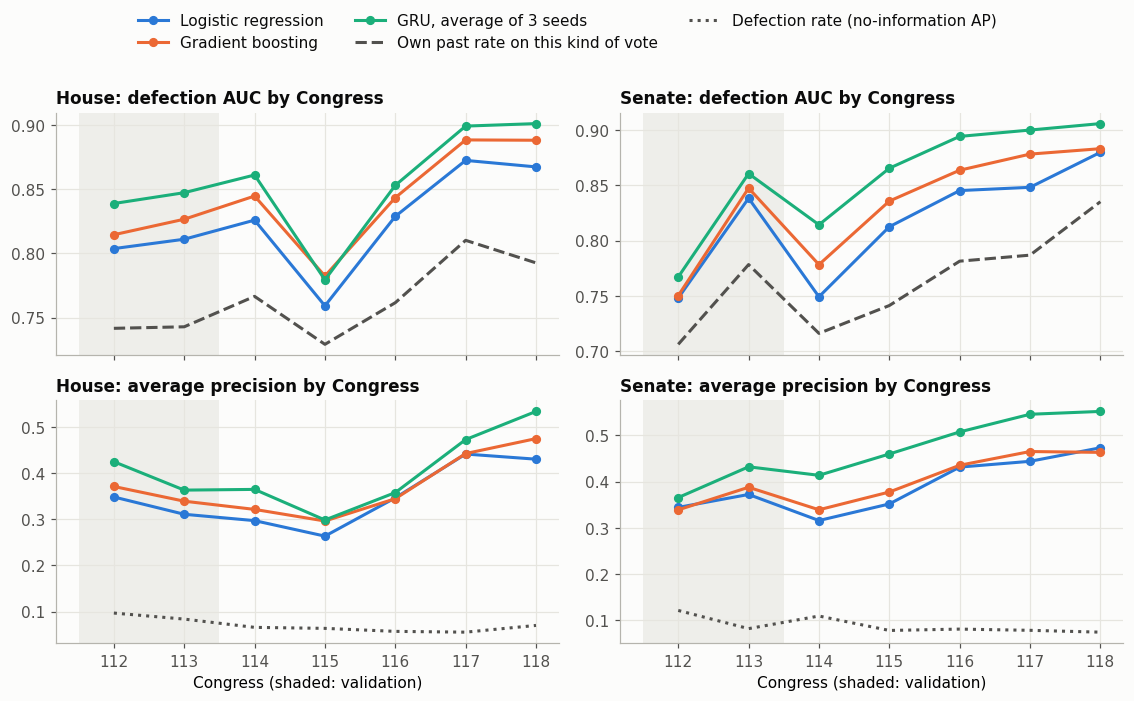

votes  defection rate  AUC logistic  AUC boosting  \
chamber congress                                                         
House   112       598059.0          0.0967        0.8038        0.8146   
        113       424894.0          0.0836        0.8111        0.8267   
        114       470861.0          0.0657        0.8260        0.8447   
        115       396462.0          0.0636        0.7592        0.7824   
        116       337409.0          0.0570        0.8289        0.8435   
        117       354861.0          0.0553        0.8725        0.8884   
        118       466216.0          0.0699        0.8674        0.8882   
Senate  112        39316.0          0.1208        0.7480        0.7501   
        113        51942.0          0.0815        0.8384        0.8476   
        114        39848.0          0.1087        0.7491        0.7782   
        115        49853.0          0.0775        0.8126        0.8358   
        116        62058.0          0.0804        0.8453        0.8638   
        117        85175.0          0.0778        0.8483        0.8784   
        118        60640.0          0.0738        0.8800        0.8833   

                  AUC gru  mean prediction logistic  mean prediction boosting  \
chamber congress                                                                
House   112        0.8389                    0.1036                    0.1023   
        113        0.8473                    0.0869                    0.0844   
        114        0.8611                    0.0746                    0.0704   
        115        0.7794                    0.0636                    0.0549   
        116        0.8531                    0.0763                    0.0670   
        117        0.8992                    0.0797                    0.0662   
        118        0.9012                    0.0886                    0.0793   
Senate  112        0.7671                    0.1319                    0.1233   
        113        0.8607                    0.0969                    0.0885   
        114        0.8143                    0.1095                    0.0990   
        115        0.8656                    0.0946                    0.0860   
        116        0.8944                    0.0978                    0.0894   
        117        0.9002                    0.0941                    0.0897   
        118        0.9060                    0.1006                    0.0898   

                  mean prediction gru  
chamber congress                       
House   112                    0.1065  
        113                    0.0902  
        114                    0.0777  
        115                    0.0653  
        116                    0.0733  
        117                    0.0642  
        118                    0.0762  
Senate  112                    0.1325  
        113                    0.0848  
        114                    0.1049  
        115                    0.0835  
        116                    0.0784  
        117                    0.0934  
        118                    0.0850

In [4]:
both = pd.concat([valid, test])
MAIN = {"logistic": "logistic", "boosting": "boosting", "gru": "gru_mean"}
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True)
for column, chamber in enumerate(["House", "Senate"]):
    part = both[both["chamber"] == chamber]
    for label, model in MAIN.items():
        by = part.groupby("congress").apply(lambda g: pd.Series({
            "auc": roc_auc_score(g["defected"], g[f"p_{model}"]), "ap": average_precision_score(g["defected"], g[f"p_{model}"])}))
        axes[0, column].plot(by.index, by["auc"], marker="o", markersize=5, color=MODEL_COLORS[label], label=NAMES[model])
        axes[1, column].plot(by.index, by["ap"], marker="o", markersize=5, color=MODEL_COLORS[label], label=NAMES[model])
    own = part.groupby("congress").apply(lambda g: roc_auc_score(g["defected"], g["p_own_past_rate"]))
    axes[0, column].plot(own.index, own, color=NEUTRAL, linestyle="--", label=NAMES["own_past_rate"])
    rate = part.groupby("congress")["defected"].mean()
    axes[1, column].plot(rate.index, rate, color=NEUTRAL, linestyle=":", label="Defection rate (no-information AP)")
    axes[0, column].set_title(f"{chamber}: defection AUC by Congress")
    axes[1, column].set_title(f"{chamber}: average precision by Congress")
    for row in range(2):
        axes[row, column].axvspan(111.5, 113.5, color="#e6e5df", alpha=0.6, lw=0)
axes[1, 0].set_xlabel("Congress (shaded: validation)")
axes[1, 1].set_xlabel("Congress (shaded: validation)")
handles, labels = axes[0, 0].get_legend_handles_labels()
handles2, labels2 = axes[1, 0].get_legend_handles_labels()
fig.legend(handles + handles2[-1:], labels + labels2[-1:], loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()
by_congress = both.groupby(["chamber", "congress"]).apply(lambda g: pd.Series({
    "votes": len(g), "defection rate": g["defected"].mean(),
    **{f"AUC {label}": roc_auc_score(g["defected"], g[f"p_{m}"]) for label, m in MAIN.items()},
    **{f"mean prediction {label}": g[f"p_{m}"].mean() for label, m in MAIN.items()}}))
display(by_congress.round(4))


*Commentary pending: time.*

## Calibration

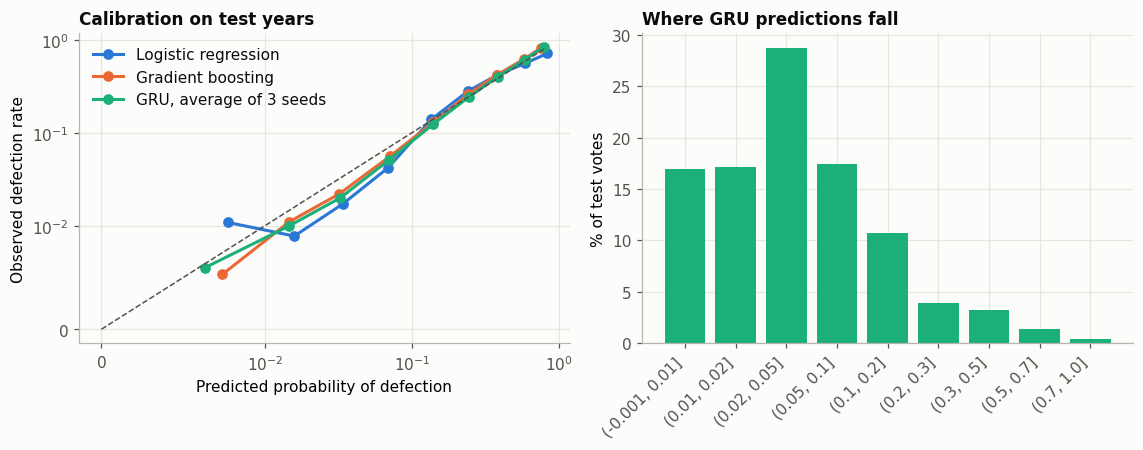

logistic                   boosting                   \
               predicted observed   votes predicted observed   votes   
(-0.001, 0.01]    0.0077   0.0109   28477    0.0074   0.0053  298613   
(0.01, 0.02]      0.0159   0.0090  225979    0.0147   0.0111  449694   
(0.02, 0.05]      0.0340   0.0172  864261    0.0320   0.0220  708787   
(0.05, 0.1]       0.0689   0.0420  755433    0.0709   0.0558  403387   
(0.1, 0.2]        0.1360   0.1395  293332    0.1404   0.1300  273085   
(0.2, 0.3]        0.2417   0.2808   73305    0.2419   0.2583   93652   
(0.3, 0.5]        0.3803   0.4170   48864    0.3828   0.4220   66546   
(0.5, 0.7]        0.5878   0.5572   18750    0.5843   0.6230   24205   
(0.7, 1.0]        0.8373   0.7117   14982    0.7542   0.8149    5414   

                     gru                   
               predicted observed   votes  
(-0.001, 0.01]    0.0063   0.0059  393650  
(0.01, 0.02]      0.0147   0.0100  398625  
(0.02, 0.05]      0.0327   0.0201  667152  
(0.05, 0.1]       0.0705   0.0515  404127  
(0.1, 0.2]        0.1398   0.1238  249727  
(0.2, 0.3]        0.2438   0.2414   91864  
(0.3, 0.5]        0.3837   0.3990   76410  
(0.5, 0.7]        0.5855   0.6115   31691  
(0.7, 1.0]        0.7874   0.8300   10137

In [5]:
bins = np.array([0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
rows = {}
for label, model in MAIN.items():
    p = test[f"p_{model}"]
    groups = pd.cut(p, bins, include_lowest=True)
    curve = test.groupby(groups, observed=True).agg(predicted=(f"p_{model}", "mean"), observed=("defected", "mean"), votes=("defected", "size"))
    rows[label] = curve
    axes[0].plot(curve["predicted"], curve["observed"], marker="o", markersize=6, color=MODEL_COLORS[label], label=NAMES[model])
axes[0].plot([0, 0.8], [0, 0.8], color=NEUTRAL, linestyle="--", linewidth=1)
axes[0].set_xscale("symlog", linthresh=0.01)
axes[0].set_yscale("symlog", linthresh=0.01)
axes[0].set_xlabel("Predicted probability of defection")
axes[0].set_ylabel("Observed defection rate")
axes[0].set_title("Calibration on test years")
axes[0].legend()
counts = rows["gru"]["votes"]
axes[1].bar(range(len(counts)), counts / counts.sum() * 100, color=MODEL_COLORS["gru"], width=0.8)
axes[1].set_xticks(range(len(counts)), [str(i) for i in counts.index], rotation=45, ha="right")
axes[1].set_ylabel("% of test votes")
axes[1].set_title("Where GRU predictions fall")
fig.tight_layout()
plt.show()
display(pd.concat(rows, axis=1).round(4))


*Commentary pending: calibration.*

## Where the models help

In [6]:
def ranking(part, models=("own_past_rate", "logistic", "boosting", "gru_mean")):
    if part["defected"].nunique() < 2:
        return pd.Series(dtype=float)
    out = {"votes": len(part), "defection rate": part["defected"].mean()}
    for m in models:
        out[f"AP {NAMES[m]}"] = average_precision_score(part["defected"], part[f"p_{m}"])
    for m in models:
        out[f"AUC {NAMES[m]}"] = roc_auc_score(part["defected"], part[f"p_{m}"])
    return pd.Series(out)


print("By kind of roll call (test years):")
display(test.groupby("party_opposed").apply(ranking).rename(index={True: "party-opposed", False: "parties agree or one tied"}).round(4))
print("By vote type (test years):")
display(test.groupby(["chamber", "vote_type"], observed=True).apply(ranking).dropna(how="all").query("votes >= 5000").round(4))
test_ = test.assign(experience=np.select([test["prior_votes"] < 100, test["tenure"] == 0], ["first 100 votes", "rest of first Congress"], "returning"))
print("By how much history the member has (test years):")
display(test_.groupby("experience").apply(ranking).round(4))
print("By party and region (test years):")
display(test.groupby(["party", "region"], observed=True).apply(ranking).query("votes >= 20000").round(4))


By kind of roll call (test years):


,votes,defection rate,AP Own past rate on this kind of vote,AP Logistic regression,AP Gradient boosting,"AP GRU, average of 3 seeds",AUC Own past rate on this kind of vote,AUC Logistic regression,AUC Gradient boosting,"AUC GRU, average of 3 seeds"
party_opposed,,,,,,,,,,
parties agree or one tied,461727.0,0.1354,0.4168,0.4712,0.4690,0.5229,0.7805,0.8254,0.8202,0.8479
party-opposed,1861656.0,0.0480,0.1502,0.2841,0.3245,0.3576,0.7328,0.8027,0.8372,0.8483


By vote type (test years):


votes  defection rate  \
chamber vote_type                                     
House   amendment          793690.0          0.0855   
        conference report   10451.0          0.0975   
        other               21201.0          0.0483   
        passage            288268.0          0.0581   
        procedural         439363.0          0.0351   
        resolution         238635.0          0.0127   
        suspension         228749.0          0.0974   
        veto override        5452.0          0.0479   
Senate  amendment           45891.0          0.0845   
        cloture             98322.0          0.0833   
        nomination          84307.0          0.0803   
        passage              7922.0          0.1386   
        procedural          48778.0          0.0757   
        resolution           8283.0          0.0491   

                           AP Own past rate on this kind of vote  \
chamber vote_type                                                  
House   amendment                                         0.2953   
        conference report                                 0.2427   
        other                                             0.2398   
        passage                                           0.2341   
        procedural                                        0.1742   
        resolution                                        0.0917   
        suspension                                        0.4181   
        veto override                                     0.2824   
Senate  amendment                                         0.2530   
        cloture                                           0.2893   
        nomination                                        0.2832   
        passage                                           0.3381   
        procedural                                        0.2476   
        resolution                                        0.1966   

                           AP Logistic regression  AP Gradient boosting  \
chamber vote_type                                                         
House   amendment                          0.3682                0.3894   
        conference report                  0.3200                0.3157   
        other                              0.2490                0.2551   
        passage                            0.3184                0.3456   
        procedural                         0.2249                0.2432   
        resolution                         0.1532                0.1954   
        suspension                         0.4938                0.5037   
        veto override                      0.3012                0.3882   
Senate  amendment                          0.2755                0.2838   
        cloture                            0.4156                0.4343   
        nomination                         0.5603                0.5236   
        passage                            0.4744                0.5482   
        procedural                         0.3075                0.3104   
        resolution                         0.1988                0.2657   

                           AP GRU, average of 3 seeds  \
chamber vote_type                                       
House   amendment                              0.4439   
        conference report                      0.3185   
        other                                  0.2438   
        passage                                0.3394   
        procedural                             0.2706   
        resolution                             0.1836   
        suspension                             0.5316   
        veto override                          0.4360   
Senate  amendment                              0.3338   
        cloture                                0.4778   
        nomination                             0.6610   
        passage                                0.6318   
        procedural                             0.3677   
    

By how much history the member has (test years):


,votes,defection rate,AP Own past rate on this kind of vote,AP Logistic regression,AP Gradient boosting,"AP GRU, average of 3 seeds",AUC Own past rate on this kind of vote,AUC Logistic regression,AUC Gradient boosting,"AUC GRU, average of 3 seeds"
experience,,,,,,,,,,
first 100 votes,42830.0,0.0425,0.2150,0.2751,0.3052,0.2939,0.7908,0.8041,0.8347,0.8437
rest of first Congress,296520.0,0.0784,0.3428,0.4163,0.4374,0.4561,0.8026,0.8388,0.8588,0.8627
returning,1984033.0,0.0639,0.2626,0.3591,0.3777,0.4244,0.7677,0.8289,0.8487,0.8637


By party and region (test years):


votes  defection rate  \
party region                                
D     Border      67838.0          0.0448   
      Midwest    184371.0          0.0474   
      Northeast  297021.0          0.0407   
      South      209888.0          0.0450   
      West       358766.0          0.0437   
R     Border     112512.0          0.0822   
      Midwest    280039.0          0.0773   
      Northeast  115345.0          0.1210   
      South      500832.0          0.0794   
      West       196771.0          0.0932   

                 AP Own past rate on this kind of vote  \
party region                                             
D     Border                                    0.1690   
      Midwest                                   0.1756   
      Northeast                                 0.1568   
      South                                     0.1322   
      West                                      0.1533   
R     Border                                    0.3514   
      Midwest                                   0.2295   
      Northeast                                 0.2933   
      South                                     0.3594   
      West                                      0.3518   

                 AP Logistic regression  AP Gradient boosting  \
party region                                                    
D     Border                     0.2720                0.3018   
      Midwest                    0.2729                0.2872   
      Northeast                  0.2484                0.2609   
      South                      0.2328                0.2560   
      West                       0.2448                0.2610   
R     Border                     0.4452                0.4635   
      Midwest                    0.3278                0.3506   
      Northeast                  0.4649                0.5119   
      South                      0.4226                0.4335   
      West                       0.4517                0.4715   

                 AP GRU, average of 3 seeds  \
party region                                  
D     Border                         0.3442   
      Midwest                        0.3230   
      Northeast                      0.2922   
      South                          0.2806   
      West                           0.2955   
R     Border                         0.4999   
      Midwest                        0.3952   
      Northeast                      0.5494   
      South                          0.4841   
      West                           0.5171   

                 AUC Own past rate on this kind of vote  \
party region                                              
D     Border                                     0.7766   
      Midwest                                    0.7697   
      Northeast                                  0.7565   
      South                                      0.7289   
      West                                       0.7569   
R     Border                                     0.7679   
      Midwest                                    0.7206   
      Northeast                                  0.7223   
      South                                      0.8068   
      West                                       0.7606   

                 AUC Logistic regression  AUC Gradient boosting  \
party region                                                      
D     Border                      0.8283                 0.8448   
      Midwest                     0.8174                 0.8283   
      Northeast                   0.8065                 0.8213   
      South                       0.7999                 0.8187   
      West                        0.8120                 0.8257   
R     Border                      0.8359                 0.8638   
      Midwest                     0.8026                 0.8275   
      Northeast                   0.8321                 0.8557   
      South                       0.8497                 

*Commentary pending: where.*

*Commentary pending: summary.*